# Iris Flower Classification Project

## Understand the project

In [3]:
from IPython.display import Image
Image(url='https://editor.analyticsvidhya.com/uploads/51518iris%20img1.png', width=850)

The objective is to predict the species of an Iris flower based on four measurements.
There are three species:
- Setosa
- Versicolor
- Virginica

In [27]:
# Import the libraries
from sklearn.datasets import load_iris
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Load the dataset

In [28]:
# Load the dataset
# Load the Iris dataset
iris = load_iris(as_frame=True)

# Convert the dataset into a DataFrame
df = iris.frame.copy()

# Display the first five rows
print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


In [29]:
# Rename the columns
df.columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width",
    "target"
]

print(df.head())

   sepal_length  sepal_width  petal_length  petal_width  target
0           5.1          3.5           1.4          0.2       0
1           4.9          3.0           1.4          0.2       0
2           4.7          3.2           1.3          0.2       0
3           4.6          3.1           1.5          0.2       0
4           5.0          3.6           1.4          0.2       0


## Convert numeric labels into species names

In [22]:
# Map target numbers to species names
species_names = dict(enumerate(iris.target_names))

df["species"] = df["target"].map(species_names)

# Display the first five rows
print(df.head())

   sepal_length  sepal_width  petal_length  petal_width  target species
0           5.1          3.5           1.4          0.2       0  setosa
1           4.9          3.0           1.4          0.2       0  setosa
2           4.7          3.2           1.3          0.2       0  setosa
3           4.6          3.1           1.5          0.2       0  setosa
4           5.0          3.6           1.4          0.2       0  setosa


# Exploratory Data Analysis (EDA)

## Check the dataset structure

In [32]:

# Display the first five rows
print("First five rows:")
print(df.head())

# Display the last five rows
print("\nLast five rows:")
print(df.tail())

# Check the number of rows and columns
print("\nDataset shape:", df.shape)

# Check column names and data types
print("\nDataset information:")
df.info()

First five rows:
   sepal_length  sepal_width  petal_length  petal_width  target species
0           5.1          3.5           1.4          0.2       0  setosa
1           4.9          3.0           1.4          0.2       0  setosa
2           4.7          3.2           1.3          0.2       0  setosa
3           4.6          3.1           1.5          0.2       0  setosa
4           5.0          3.6           1.4          0.2       0  setosa

Last five rows:
     sepal_length  sepal_width  petal_length  petal_width  target    species
145           6.7          3.0           5.2          2.3       2  virginica
146           6.3          2.5           5.0          1.9       2  virginica
147           6.5          3.0           5.2          2.0       2  virginica
148           6.2          3.4           5.4          2.3       2  virginica
149           5.9          3.0           5.1          1.8       2  virginica

Dataset shape: (150, 6)

Dataset information:
<class 'pandas.core.frame

## Check missing values

In [35]:
# Count missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Calculate the percentage of missing values
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing values percentage:")
print(missing_percentage)

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
target          0
species         0
dtype: int64

Missing values percentage:
sepal_length    0.0
sepal_width     0.0
petal_length    0.0
petal_width     0.0
target          0.0
species         0.0
dtype: float64


## Check duplicate records

In [36]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

# Display duplicate rows, if any
duplicates = df[df.duplicated()]

print("\nDuplicate records:")
print(duplicates)

Number of duplicate rows: 1

Duplicate records:
     sepal_length  sepal_width  petal_length  petal_width  target    species
142           5.8          2.7           5.1          1.9       2  virginica


## Analyze the species distribution

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


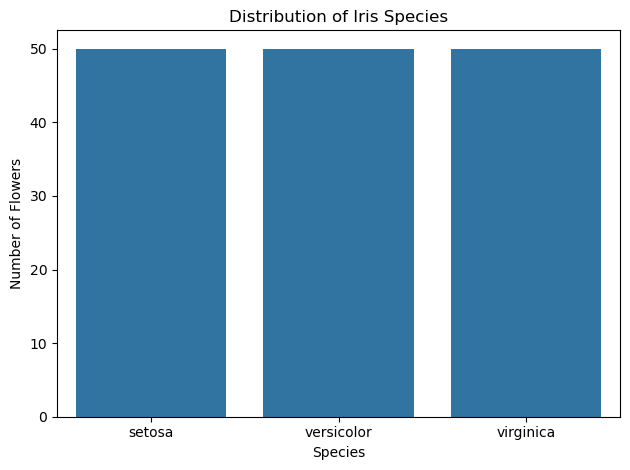

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count flowers by species
species_counts = df["species"].value_counts()

print(species_counts)

# Create a bar chart
sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Flowers")
plt.tight_layout()
plt.show()

## Calculate descriptive statistics

In [38]:
# Select the four measurement columns
features = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

# Calculate summary statistics
print(df[features].describe().round(2))

       sepal_length  sepal_width  petal_length  petal_width
count        150.00       150.00        150.00       150.00
mean           5.84         3.06          3.76         1.20
std            0.83         0.44          1.77         0.76
min            4.30         2.00          1.00         0.10
25%            5.10         2.80          1.60         0.30
50%            5.80         3.00          4.35         1.30
75%            6.40         3.30          5.10         1.80
max            7.90         4.40          6.90         2.50


## Compare average measurements by species

In [39]:
# Calculate average measurements for each species
average_measurements = df.groupby("species")[features].mean()

print(average_measurements.round(2))

            sepal_length  sepal_width  petal_length  petal_width
species                                                         
setosa              5.01         3.43          1.46         0.25
versicolor          5.94         2.77          4.26         1.33
virginica           6.59         2.97          5.55         2.03


## Visualize the relationship between petal measurements

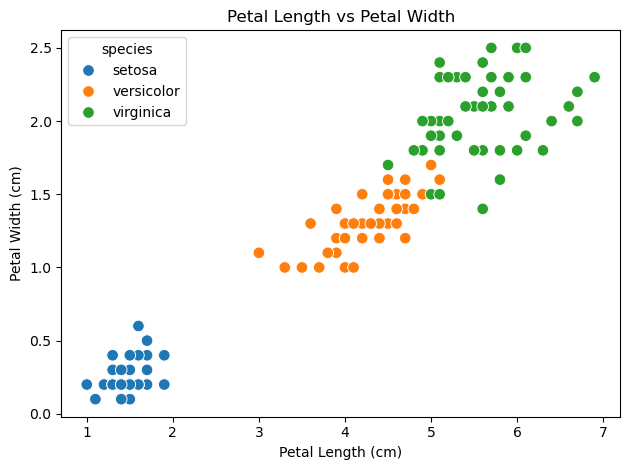

In [40]:
# Compare petal length and petal width
sns.scatterplot(
    data=df,
    x="petal_length",
    y="petal_width",
    hue="species",
    s=70
)

plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.tight_layout()
plt.show()

## Analyze feature correlations

              sepal_length  sepal_width  petal_length  petal_width
sepal_length          1.00        -0.12          0.87         0.82
sepal_width          -0.12         1.00         -0.43        -0.37
petal_length          0.87        -0.43          1.00         0.96
petal_width           0.82        -0.37          0.96         1.00


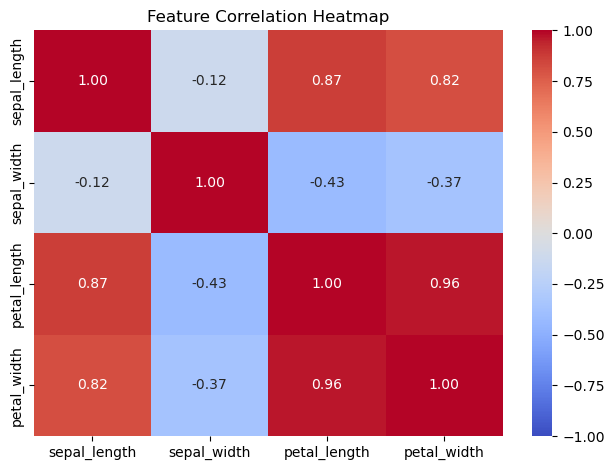

In [41]:
# Calculate correlations between measurements
correlation = df[features].corr()

print(correlation.round(2))

# Visualize correlations
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

## Data Preprocessing and Train-Test Splitting

In [43]:
from sklearn.model_selection import train_test_split

# Step 1: Select input features
X = df[
    [
        "sepal_length",
        "sepal_width",
        "petal_length",
        "petal_width"
    ]
]

# Step 2: Select the target variable
y = df["target"]

# Step 3: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 4: Check the shapes of the datasets
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# Step 5: Display sample training data
print("\nFirst five training rows:")
print(X_train.head())

print("\nFirst five target values:")
print(y_train.head())

X_train shape: (120, 4)
X_test shape: (30, 4)
y_train shape: (120,)
y_test shape: (30,)

First five training rows:
     sepal_length  sepal_width  petal_length  petal_width
8             4.4          2.9           1.4          0.2
106           4.9          2.5           4.5          1.7
76            6.8          2.8           4.8          1.4
9             4.9          3.1           1.5          0.1
89            5.5          2.5           4.0          1.3

First five target values:
8      0
106    2
76     1
9      0
89     1
Name: target, dtype: int64


## Build and Train Machine Learning Model

In [44]:
# Step 1: Import the algorithm
from sklearn.linear_model import LogisticRegression

# Step 2: Create the model
model = LogisticRegression(max_iter=200)

# Step 3: Train the model
model.fit(X_train, y_train)

# Step 4: Check whether the model was trained
print("Model training completed successfully!")

# Step 5: Display the learned classes
print("Classes learned by the model:", model.classes_)

Model training completed successfully!
Classes learned by the model: [0 1 2]


## Make Predictions and Evaluate Model Accuracy

In [45]:
# Step 1: Make predictions on test data
y_pred = model.predict(X_test)

# Step 2: Compare actual and predicted values
import pandas as pd

results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

# Step 3: Convert numeric labels into species names
species_names = {
    0: "setosa",
    1: "versicolor",
    2: "virginica"
}

results["Actual_Species"] = results["Actual"].map(species_names)
results["Predicted_Species"] = results["Predicted"].map(species_names)

# Step 4: Display sample predictions
print("First 10 predictions:")
print(results.head(10))

# Step 5: Calculate accuracy
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

# Step 6: Count correct and incorrect predictions
correct = (y_test == y_pred).sum()
incorrect = (y_test != y_pred).sum()

print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)

First 10 predictions:
     Actual  Predicted Actual_Species Predicted_Species
38        0          0         setosa            setosa
127       2          2      virginica         virginica
57        1          1     versicolor        versicolor
93        1          1     versicolor        versicolor
42        0          0         setosa            setosa
56        1          1     versicolor        versicolor
22        0          0         setosa            setosa
20        0          0         setosa            setosa
147       2          2      virginica         virginica
84        1          1     versicolor        versicolor

Model Accuracy: 96.67 %
Correct predictions: 29
Incorrect predictions: 1


## Confusion Matrix and Classification Report

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


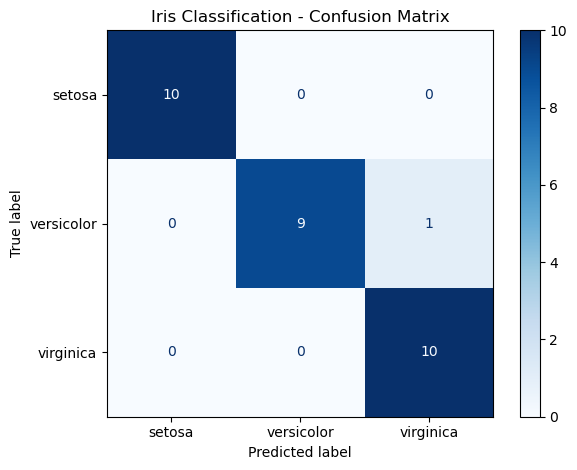


Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [46]:
# Step 1: Import evaluation tools
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
import matplotlib.pyplot as plt

# Step 2: Create the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2]
)

print("Confusion Matrix:")
print(cm)

# Step 3: Display the confusion matrix as a chart
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["setosa", "versicolor", "virginica"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Iris Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

# Step 4: Generate the classification report
report = classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    target_names=["setosa", "versicolor", "virginica"],
    zero_division=0
)

print("\nClassification Report:")
print(report)

## Compare Machine Learning Algorithms

In [47]:
# Step 1: Import libraries
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Step 2: Define the models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=200)
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

# Step 3: Train and evaluate each model
results = []

for name, classifier in models.items():
    classifier.fit(X_train, y_train)

    predictions = classifier.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

# Step 4: Create the comparison table
comparison = pd.DataFrame(results)

# Step 5: Sort by accuracy
comparison = comparison.sort_values(
    by="Accuracy",
    ascending=False
)

# Step 6: Display the results
print(comparison.round(3).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1_Score
Logistic Regression     0.933      0.933   0.933     0.933
      Decision Tree     0.933      0.933   0.933     0.933
                KNN     0.933      0.944   0.933     0.933
      Random Forest     0.900      0.902   0.900     0.900


## Cross-Validation and Selecting the Best Model

In [48]:
# Step 1: Import libraries
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, classification_report

# Step 2: Define the four models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=200)
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

# Step 3: Create 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Step 4: Select evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}

# Step 5: Evaluate each model using cross-validation
cv_results = []

for name, classifier in models.items():
    scores = cross_validate(
        classifier,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Mean Precision": scores["test_precision"].mean(),
        "Mean Recall": scores["test_recall"].mean(),
        "Mean F1": scores["test_f1"].mean()
    })

# Step 6: Display cross-validation results
cv_table = pd.DataFrame(cv_results)

cv_table = cv_table.sort_values(
    by="Mean F1",
    ascending=False
)

print("Cross-validation results:")
print(cv_table.round(3).to_string(index=False))

# Step 7: Select the model with the highest mean F1-score
best_name = cv_table.iloc[0]["Model"]
best_model = models[best_name]

print("\nSelected model:", best_name)

# Step 8: Fit the selected model on all training data
best_model.fit(X_train, y_train)

# Step 9: Evaluate once on the held-out test set
y_pred_best = best_model.predict(X_test)

print(
    "\nFinal test accuracy:",
    round(accuracy_score(y_test, y_pred_best) * 100, 2),
    "%"
)

print("\nFinal classification report:")
print(
    classification_report(
        y_test,
        y_pred_best,
        target_names=["setosa", "versicolor", "virginica"],
        zero_division=0
    )
)

Cross-validation results:
              Model  Mean Accuracy  Accuracy Std  Mean Precision  Mean Recall  Mean F1
Logistic Regression          0.958         0.026           0.964        0.958    0.958
                KNN          0.958         0.026           0.964        0.958    0.958
      Decision Tree          0.950         0.017           0.957        0.950    0.950
      Random Forest          0.950         0.031           0.959        0.950    0.949

Selected model: Logistic Regression

Final test accuracy: 93.33 %

Final classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



## Save and Load Trained Machine Learning Model

In [49]:
# Step 1: Import joblib
import joblib

# Step 2: Save the trained model
joblib.dump(best_model, "iris_model.joblib")

print("Model saved successfully!")

# Step 3: Load the saved model
loaded_model = joblib.load("iris_model.joblib")

print("Model loaded successfully!")

# Step 4: Predict one flower using its measurements
sample_flower = [[5.1, 3.5, 1.4, 0.2]]

prediction = loaded_model.predict(sample_flower)

# Step 5: Convert numeric prediction into a species name
species_names = {
    0: "setosa",
    1: "versicolor",
    2: "virginica"
}

predicted_species = species_names[int(prediction[0])]

print("Predicted flower species:", predicted_species)

Model saved successfully!
Model loaded successfully!
Predicted flower species: setosa


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


## Build a Web App for Iris Flower Classification 🌸

In [51]:
pip install streamlit pandas scikit-learn joblib


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib
from pathlib import Path

st.set_page_config(
    page_title="Iris Flower Classifier",
    page_icon="🌸"
)

model_path = Path(__file__).parent / "iris_model.joblib"
model = joblib.load(model_path)

species_names = {
    0: "Setosa",
    1: "Versicolor",
    2: "Virginica"
}

st.title("🌸 Iris Flower Classification")
st.write("Enter flower measurements below.")

sepal_length = st.number_input(
    "Sepal Length (cm)", min_value=0.0, max_value=10.0, value=5.1
)
sepal_width = st.number_input(
    "Sepal Width (cm)", min_value=0.0, max_value=10.0, value=3.5
)
petal_length = st.number_input(
    "Petal Length (cm)", min_value=0.0, max_value=10.0, value=1.4
)
petal_width = st.number_input(
    "Petal Width (cm)", min_value=0.0, max_value=10.0, value=0.2
)

if st.button("Predict Species"):
    flower = pd.DataFrame([{
        "sepal_length": sepal_length,
        "sepal_width": sepal_width,
        "petal_length": petal_length,
        "petal_width": petal_width
    }])

    prediction = int(model.predict(flower)[0])
    st.success(f"Predicted Species: {species_names[prediction]}")

Overwriting app.py


In [1]:
!streamlit run app.py


  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://192.168.1.49:8501

^C
  Stopping...
